In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('/content/Metro_Interstate_Traffic_Volume_snow_updated.csv')

df.head()

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


In [3]:
df.shape

(48204, 9)

In [4]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   holiday              61 non-null     object 
 1   temp                 48204 non-null  float64
 2   rain_1h              48204 non-null  float64
 3   snow_1h              48204 non-null  float64
 4   clouds_all           48204 non-null  int64  
 5   weather_main         48204 non-null  object 
 6   weather_description  48204 non-null  object 
 7   date_time            48204 non-null  object 
 8   traffic_volume       48204 non-null  int64  
dtypes: float64(3), int64(2), object(4)
memory usage: 3.3+ MB


,temp,rain_1h,snow_1h,clouds_all,traffic_volume
count,48204.000000,48204.000000,48204.000000,48204.000000,48204.000000
mean,281.205870,0.371475,0.101064,49.362231,3259.818355
std,13.338232,1.233681,0.591236,39.015750,1986.860670
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,272.160000,0.000000,0.000000,1.000000,1193.000000
50%,282.450000,0.000000,0.000000,64.000000,3380.000000
75%,291.806000,0.000000,0.000000,90.000000,4933.000000
max,310.070000,16.000000,5.000000,100.000000,7280.000000


**Understand the columns**

In [5]:
df.columns

Index(['holiday', 'temp', 'rain_1h', 'snow_1h', 'clouds_all', 'weather_main',
       'weather_description', 'date_time', 'traffic_volume'],
      dtype='object')

In [6]:
df.isnull().sum()

,0
holiday,48143
temp,0
rain_1h,0
snow_1h,0
clouds_all,0
weather_main,0
weather_description,0
date_time,0
traffic_volume,0


In [7]:
missing = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': df.isnull().mean() * 100
})

missing

,Missing_Count,Missing_Percentage
holiday,48143,99.873454
temp,0,0.000000
rain_1h,0,0.000000
snow_1h,0,0.000000
clouds_all,0,0.000000
weather_main,0,0.000000
weather_description,0,0.000000
date_time,0,0.000000
traffic_volume,0,0.000000


In [8]:
df['holiday'].value_counts(dropna=False)

,count
holiday,
NaN,48143
Labor Day,7
Christmas Day,6
Thanksgiving Day,6
Martin Luther King Jr Day,6
New Years Day,6
Veterans Day,5
Columbus Day,5
Memorial Day,5


In [9]:
df.duplicated().sum()

np.int64(17)

In [10]:
df.drop_duplicates(inplace=True)

Convert temperature from Kelvin to Celsius

In [11]:
df['temp_celsius'] = df['temp'] - 273.15

In [12]:
df[['temp', 'temp_celsius']].head()

,temp,temp_celsius
0,288.28,15.13
1,289.36,16.21
2,289.58,16.43
3,290.13,16.98
4,291.14,17.99


Convert date_time

In [13]:
df['date_time'] = pd.to_datetime(df['date_time'])

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 48187 entries, 0 to 48203
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   holiday              61 non-null     object        
 1   temp                 48187 non-null  float64       
 2   rain_1h              48187 non-null  float64       
 3   snow_1h              48187 non-null  float64       
 4   clouds_all           48187 non-null  int64         
 5   weather_main         48187 non-null  object        
 6   weather_description  48187 non-null  object        
 7   date_time            48187 non-null  datetime64[ns]
 8   traffic_volume       48187 non-null  int64         
 9   temp_celsius         48187 non-null  float64       
dtypes: datetime64[ns](1), float64(4), int64(2), object(3)
memory usage: 4.0+ MB


In [15]:
df['year'] = df['date_time'].dt.year
df['month'] = df['date_time'].dt.month
df['day'] = df['date_time'].dt.day
df['hour'] = df['date_time'].dt.hour
df['day_of_week'] = df['date_time'].dt.dayofweek

In [16]:
df['day_name'] = df['date_time'].dt.day_name()

**Create weekend feature**

In [17]:
df['is_weekend'] = (df['day_of_week'] >= 5).astype(int) #0 → Weekday 1 → Weekend

**Create holiday feature**

In [18]:
df['holiday'] = df['holiday'].fillna('None')

df['is_holiday'] = (df['holiday'] != 'None').astype(int)

In [19]:
print(df['holiday'].value_counts())


holiday
None                         48126
Labor Day                        7
Christmas Day                    6
Thanksgiving Day                 6
Martin Luther King Jr Day        6
New Years Day                    6
Veterans Day                     5
Columbus Day                     5
Memorial Day                     5
Washingtons Birthday             5
State Fair                       5
Independence Day                 5
Name: count, dtype: int64


In [20]:
print(df['is_holiday'].value_counts())

is_holiday
0    48126
1       61
Name: count, dtype: int64


Check traffic-volume outliers

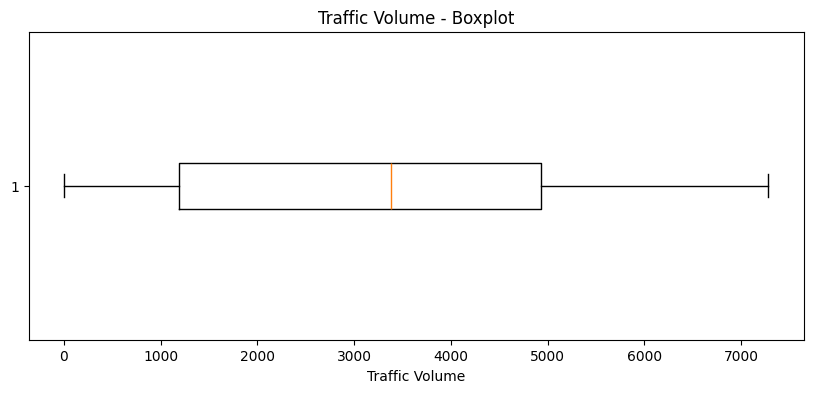

In [21]:
plt.figure(figsize=(10,4))
plt.boxplot(df['traffic_volume'], vert=False)
plt.xlabel('Traffic Volume')
plt.title('Traffic Volume - Boxplot')
plt.show()

**Basic EDA**

**Hourly traffic analysis** #Traffic volume varies significantly by hour, with clear peak periods associated with commuting hours.

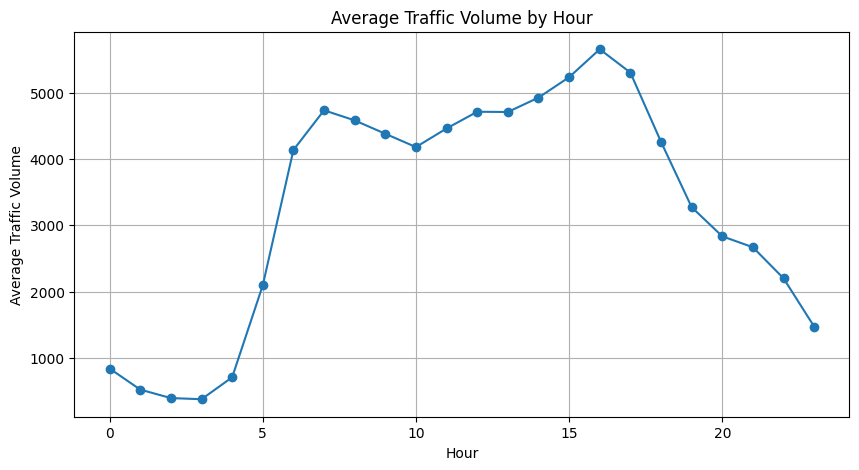

In [22]:
hourly_traffic = df.groupby('hour')['traffic_volume'].mean()

plt.figure(figsize=(10,5))
hourly_traffic.plot(marker='o')

plt.xlabel('Hour')
plt.ylabel('Average Traffic Volume')
plt.title('Average Traffic Volume by Hour')
plt.grid()
plt.show()

* Peak Hours: 4 PM, 3 PM, 5 PM
* Week traffic hours: 12-4 AM, 11 PM

**Daily traffic analysis**  #Which day has the highest average traffic?

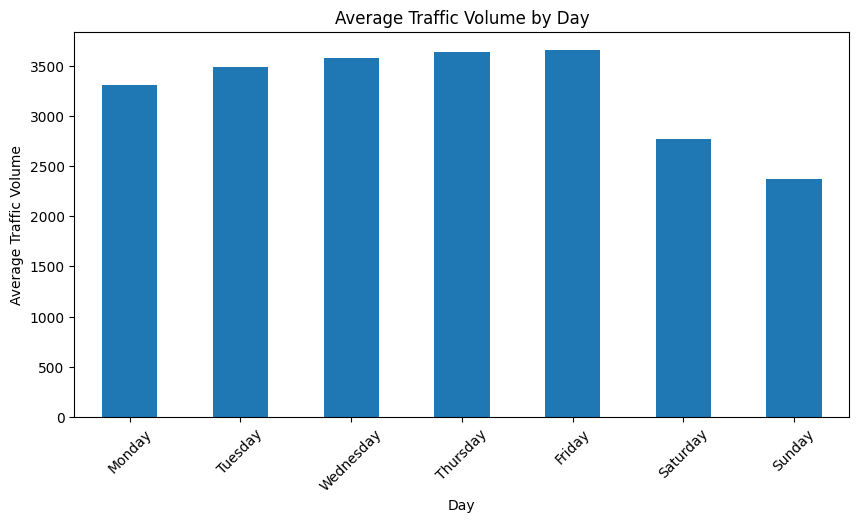

In [23]:
day_order = [
    'Monday',
    'Tuesday',
    'Wednesday',
    'Thursday',
    'Friday',
    'Saturday',
    'Sunday'
]

daily_traffic = (
    df.groupby('day_name')['traffic_volume']
      .mean()
      .reindex(day_order)
)

plt.figure(figsize=(10,5))
daily_traffic.plot(kind='bar')

plt.xlabel('Day')
plt.ylabel('Average Traffic Volume')
plt.title('Average Traffic Volume by Day')
plt.xticks(rotation=45)
plt.show()

**Weekday vs weekend analysis**    

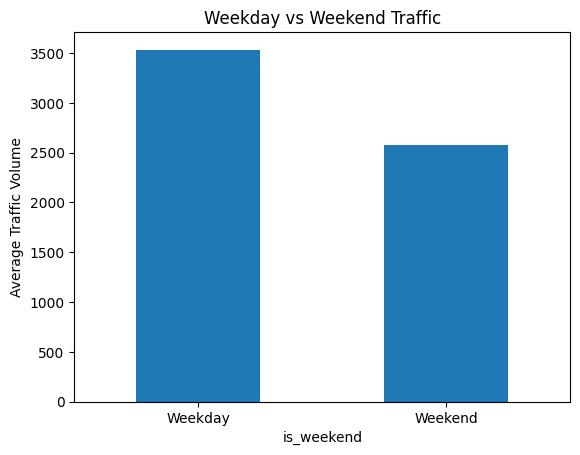

In [24]:
weekend_traffic = df.groupby('is_weekend')['traffic_volume'].mean()

weekend_traffic.plot(kind='bar')

plt.xticks([0,1], ['Weekday', 'Weekend'], rotation=0)
plt.ylabel('Average Traffic Volume')
plt.title('Weekday vs Weekend Traffic')
plt.show()

**Monthly traffic pattern**  #This shows whether traffic changes seasonally.

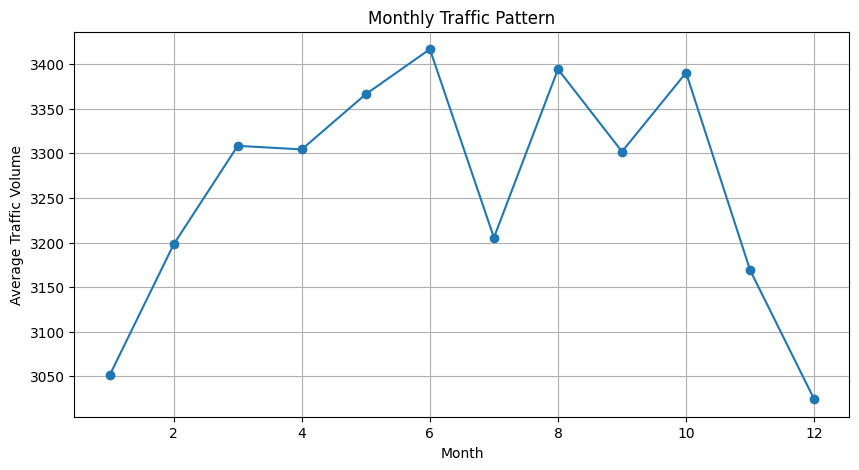

In [25]:
monthly_traffic = df.groupby('month')['traffic_volume'].mean()

monthly_traffic.plot(
    kind='line',
    marker='o',
    figsize=(10,5)
)

plt.xlabel('Month')
plt.ylabel('Average Traffic Volume')
plt.title('Monthly Traffic Pattern')
plt.grid()
plt.show()

**Weather vs traffic analysis**

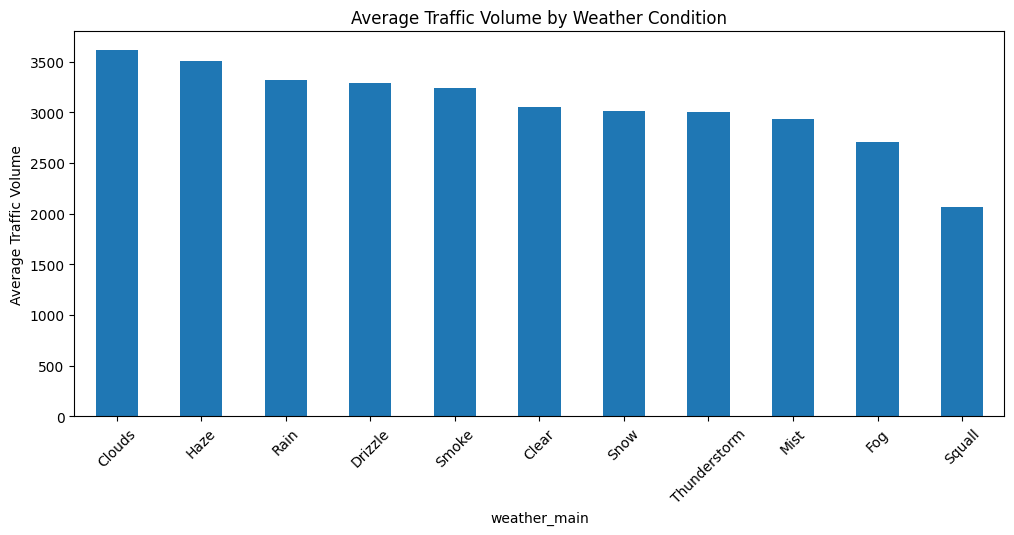

In [26]:
weather_traffic = (
    df.groupby('weather_main')['traffic_volume']
      .mean()
      .sort_values(ascending=False)
)

weather_traffic.plot(
    kind='bar',
    figsize=(12,5)
)

plt.ylabel('Average Traffic Volume')
plt.title('Average Traffic Volume by Weather Condition')
plt.xticks(rotation=45)
plt.show()

**Rain vs traffic**

Create new feature # **is_raining**

In [27]:
df['is_raining'] = (df['rain_1h'] > 0).astype(int)

In [28]:
df.groupby('is_raining')['traffic_volume'].mean()

,traffic_volume
is_raining,
0,3256.457888
1,3274.308405


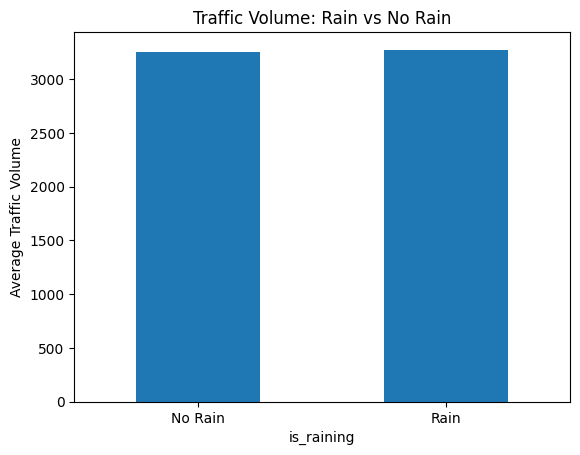

In [29]:
df.groupby('is_raining')['traffic_volume'].mean().plot(kind='bar')

plt.xticks([0,1], ['No Rain', 'Rain'], rotation=0)
plt.ylabel('Average Traffic Volume')
plt.title('Traffic Volume: Rain vs No Rain')
plt.show()

**Holiday vs normal-day traffic**

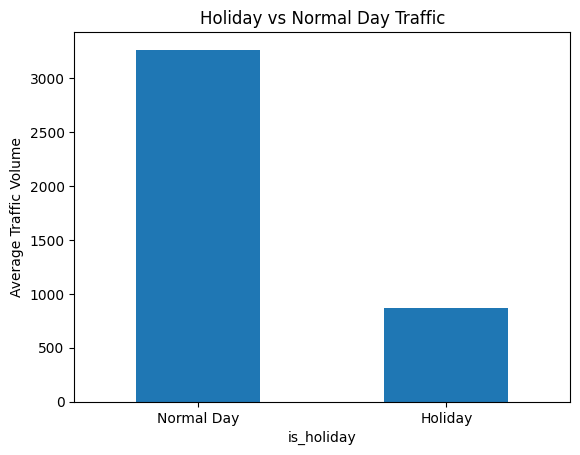

In [30]:
df.groupby('is_holiday')['traffic_volume'].mean().plot(kind='bar')

plt.xticks([0,1], ['Normal Day', 'Holiday'], rotation=0)
plt.ylabel('Average Traffic Volume')
plt.title('Holiday vs Normal Day Traffic')
plt.show()

**Create congestion levels**

In [31]:
df['congestion_level'] = pd.qcut(
    df['traffic_volume'],
    q=3,
    labels=['Low', 'Moderate', 'High']
)

In [32]:
df['congestion_level'].value_counts() #This divides the dataset into four approximately equal groups.

,count
congestion_level,
Moderate,16065
Low,16063
High,16059


In [33]:
def congestion_level(volume):
    if volume < 2000:
        return 'Low'
    elif volume < 4000:
        return 'Moderate'
    else:
        return 'High'

df['congestion_level'] = df['traffic_volume'].apply(congestion_level)

**Check congestion-level distribution**

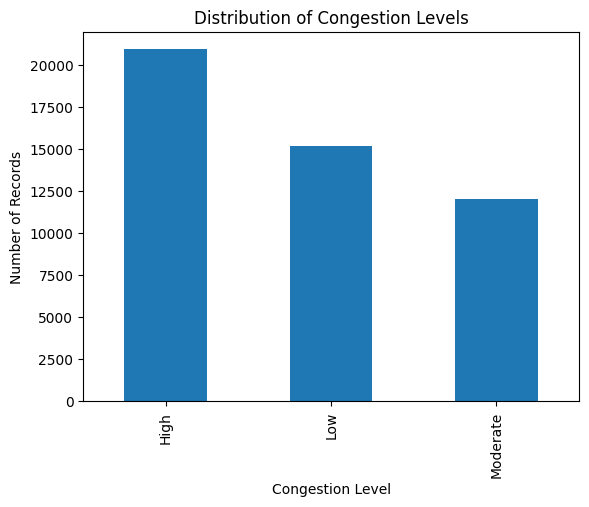

In [34]:
df['congestion_level'].value_counts().plot(kind='bar')

plt.xlabel('Congestion Level')
plt.ylabel('Number of Records')
plt.title('Distribution of Congestion Levels')
plt.show()

**Day × hour congestion heatmap**

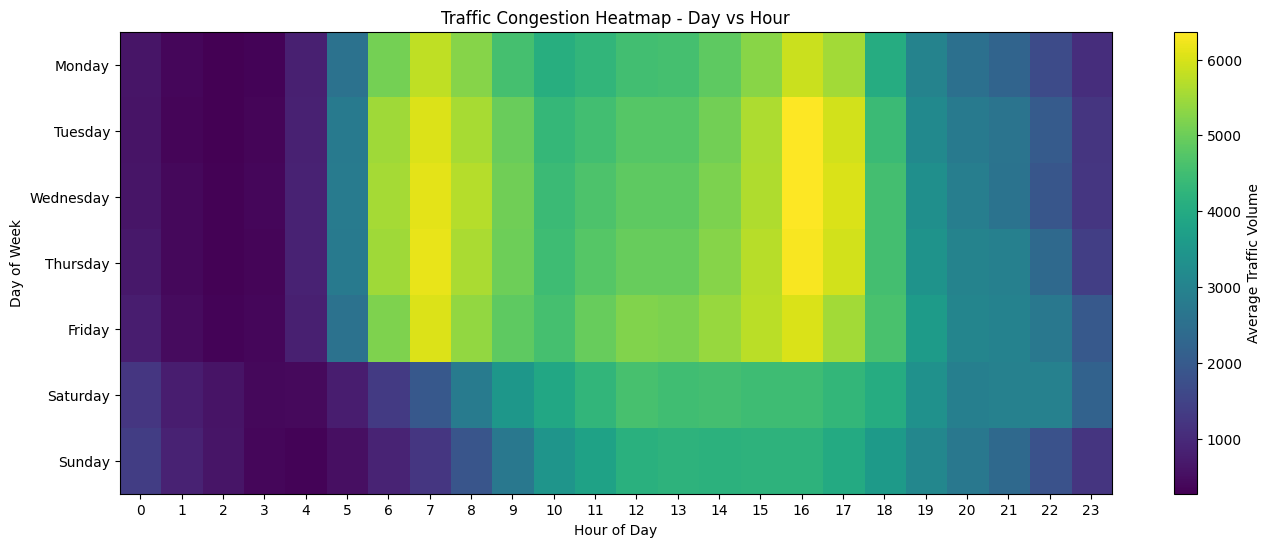

In [35]:
heatmap_data = df.pivot_table(
    values='traffic_volume',
    index='day_name',
    columns='hour',
    aggfunc='mean'
)

heatmap_data = heatmap_data.reindex(day_order)

plt.figure(figsize=(16,6))
plt.imshow(heatmap_data, aspect='auto')

plt.colorbar(label='Average Traffic Volume')
plt.xticks(range(24), range(24))
plt.yticks(range(7), day_order)

plt.xlabel('Hour of Day')
plt.ylabel('Day of Week')
plt.title('Traffic Congestion Heatmap - Day vs Hour')

plt.show()  #It shows which day + hour combinations experience the heaviest traffic?

**Find the busiest hours**

In [36]:
df.groupby('hour')['traffic_volume'] \
  .mean() \
  .sort_values(ascending=False) \
  .head(10) #Top 10 busiest hours of day.

,traffic_volume
hour,
16,5663.756539
17,5310.076048
15,5240.459907
14,4931.888776
7,4740.181337
12,4718.031730
13,4714.652836
8,4587.497115
11,4465.569231


In [37]:
busiest_periods = (
    df.groupby(['day_name', 'hour'])['traffic_volume']
      .mean()
      .sort_values(ascending=False)
      .head(10)
      .reset_index()
)

busiest_periods  #7 AM → Morning rush hour
#4 PM (hour 16) → Evening rush hour
#5 PM (hour 17) → Evening rush hour

,day_name,hour,traffic_volume
0,Wednesday,16,6367.467577
1,Tuesday,16,6366.796992
2,Thursday,16,6313.568421
3,Thursday,7,6168.611486
4,Wednesday,7,6120.721649
5,Tuesday,7,6043.778947
6,Friday,7,6038.904437
7,Friday,16,6026.752650
8,Wednesday,17,6018.631387
9,Thursday,17,5950.033457


In [38]:
df.head()


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume,temp_celsius,year,month,day,hour,day_of_week,day_name,is_weekend,is_holiday,is_raining,congestion_level
0,None,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545,15.13,2012,10,2,9,1,Tuesday,0,0,0,High
1,None,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516,16.21,2012,10,2,10,1,Tuesday,0,0,0,High
2,None,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767,16.43,2012,10,2,11,1,Tuesday,0,0,0,High
3,None,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026,16.98,2012,10,2,12,1,Tuesday,0,0,0,High
4,None,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918,17.99,2012,10,2,13,1,Tuesday,0,0,0,High


**Correlation analysis**

In [39]:
numeric_cols = [
    'temp_celsius',
    'rain_1h',
    'snow_1h',
    'clouds_all',
    'hour',
    'day_of_week',
    'traffic_volume'
]

corr = df[numeric_cols].corr()

corr

,temp_celsius,rain_1h,snow_1h,clouds_all,hour,day_of_week,traffic_volume
temp_celsius,1.000000,0.177131,-0.158350,-0.101968,0.112048,-0.007824,0.130161
rain_1h,0.177131,1.000000,-0.051307,0.195470,-0.000295,-0.015047,-0.011281
snow_1h,-0.158350,-0.051307,1.000000,0.154595,-0.004537,-0.006123,-0.021780
clouds_all,-0.101968,0.195470,0.154595,1.000000,0.054522,-0.039816,0.067138
hour,0.112048,-0.000295,-0.004537,0.054522,1.000000,-0.003808,0.352300
day_of_week,-0.007824,-0.015047,-0.006123,-0.039816,-0.003808,1.000000,-0.149551
traffic_volume,0.130161,-0.011281,-0.021780,0.067138,0.352300,-0.149551,1.000000


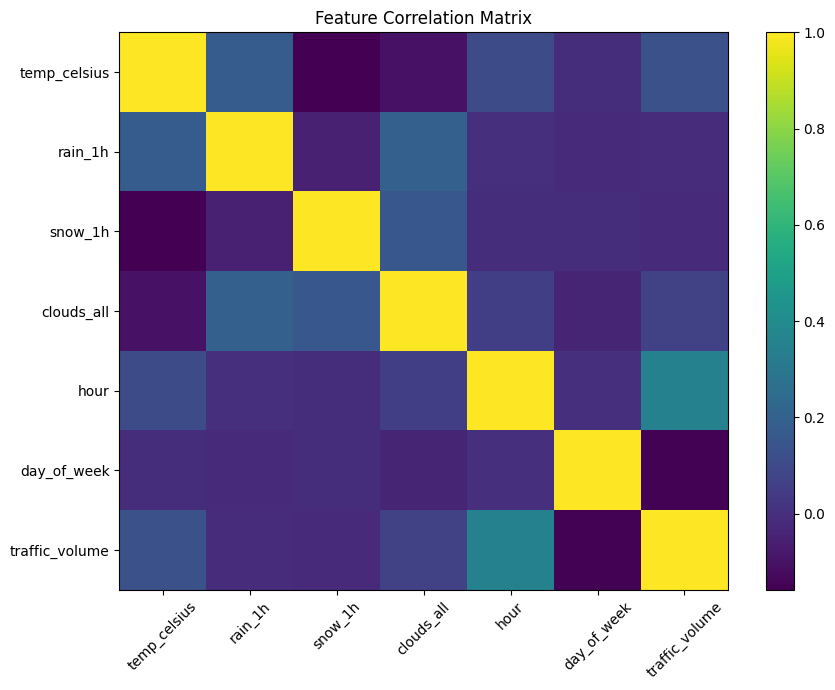

In [40]:
plt.figure(figsize=(9,7))
plt.imshow(corr, aspect='auto')
plt.colorbar()

plt.xticks(
    range(len(corr.columns)),
    corr.columns,
    rotation=45
)

plt.yticks(
    range(len(corr.columns)),
    corr.columns
)

plt.title('Feature Correlation Matrix')
plt.tight_layout()
plt.show()

**Feature engineering for the ML model**

Create lag variables : can actually help predict future traffic.

In [41]:
df = df.sort_values('date_time')

df['traffic_lag_1'] = df['traffic_volume'].shift(1)
df['traffic_lag_2'] = df['traffic_volume'].shift(2)
df['traffic_lag_24'] = df['traffic_volume'].shift(24)

Create rolling averages:

In [42]:
df['rolling_3h_avg'] = (
    df['traffic_volume']
      .shift(1)
      .rolling(3)
      .mean()
)

df['rolling_6h_avg'] = (
    df['traffic_volume']
      .shift(1)
      .rolling(6)
      .mean()
)

**Create the 1-hour-ahead target**

In [43]:
df['traffic_1h_ahead'] = df['traffic_volume'].shift(-1)

Lag and rolling operations naturally create missing rows.  #Remove missing values

In [44]:
df[[
    'traffic_lag_1',
    'traffic_lag_24',
    'rolling_3h_avg',
    'traffic_1h_ahead'
]].isnull().sum()

,0
traffic_lag_1,1
traffic_lag_24,24
rolling_3h_avg,3
traffic_1h_ahead,1


Modelling

In [45]:
model_df = df.dropna().copy()

baseline features

In [46]:
features = [
    'hour',
    'day_of_week',
    'month',
    'is_weekend',
    'is_holiday',
    'temp_celsius',
    'rain_1h',
    'snow_1h',
    'clouds_all',
    'traffic_lag_1',
    'traffic_lag_2',
    'traffic_lag_24',
    'rolling_3h_avg',
    'rolling_6h_avg'
]

X = model_df[features]
y = model_df['traffic_1h_ahead']

Train/test split - this is time-series data, don't use a random split as your primary evaluation.

In [47]:
split_index = int(len(model_df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

Gradient Boosting baseline

In [48]:
from sklearn.ensemble import GradientBoostingRegressor

gb_model = GradientBoostingRegressor(
    random_state=42
)

gb_model.fit(X_train, y_train)

GradientBoostingRegressor(random_state=42)

In [49]:
y_pred = gb_model.predict(X_test)

Evaluate using MAE

In [50]:
from sklearn.metrics import mean_absolute_error

In [51]:
mae = mean_absolute_error(y_test, y_pred)

print("Gradient Boosting MAE:", mae)

Gradient Boosting MAE: 334.82638713462285


In [52]:
from sklearn.metrics import mean_squared_error, r2_score

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE :", mae)
print("RMSE:", rmse)
print("R²  :", r2)

MAE : 334.82638713462285
RMSE: 482.36624971351546
R²  : 0.9399252951721903


**Actual vs predicted graph**

In [53]:
results = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

results.head()

,Actual,Predicted
0,1713.0,1756.858555
1,1713.0,1271.523546
2,1068.0,1357.615667
3,611.0,798.269604
4,362.0,549.526403


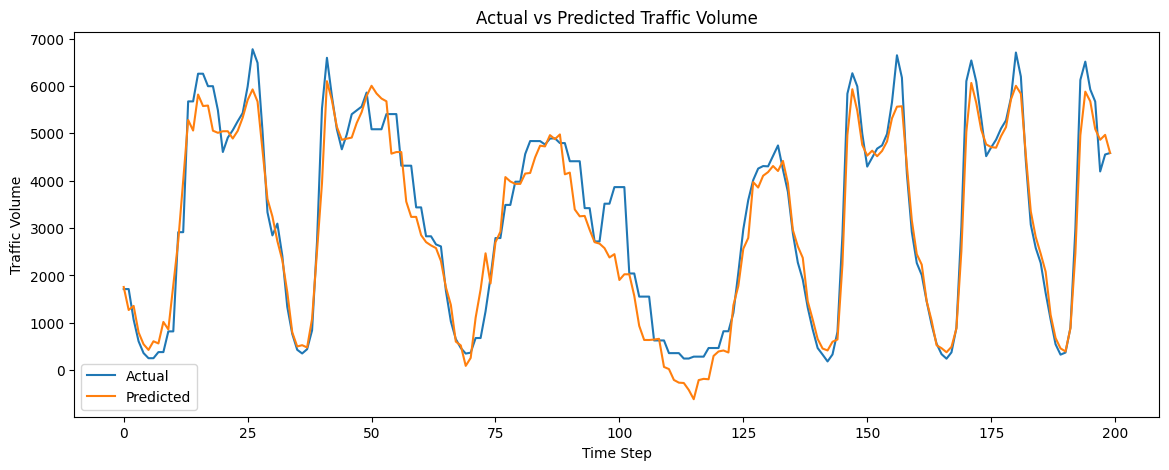

In [54]:
plt.figure(figsize=(14,5))

plt.plot(results['Actual'][:200], label='Actual')
plt.plot(results['Predicted'][:200], label='Predicted')

plt.xlabel('Time Step')
plt.ylabel('Traffic Volume')
plt.title('Actual vs Predicted Traffic Volume')
plt.legend()
plt.show()

**Feature importance** - which variables are influencing predictions




In [55]:
importance = pd.DataFrame({
    'Feature': features,
    'Importance': gb_model.feature_importances_
})

importance = importance.sort_values(
    'Importance',
    ascending=False
)

importance

,Feature,Importance
9,traffic_lag_1,0.570713
0,hour,0.355365
10,traffic_lag_2,0.017566
3,is_weekend,0.016006
1,day_of_week,0.013838
12,rolling_3h_avg,0.013740
13,rolling_6h_avg,0.009739
11,traffic_lag_24,0.001312
5,temp_celsius,0.000655
2,month,0.000625


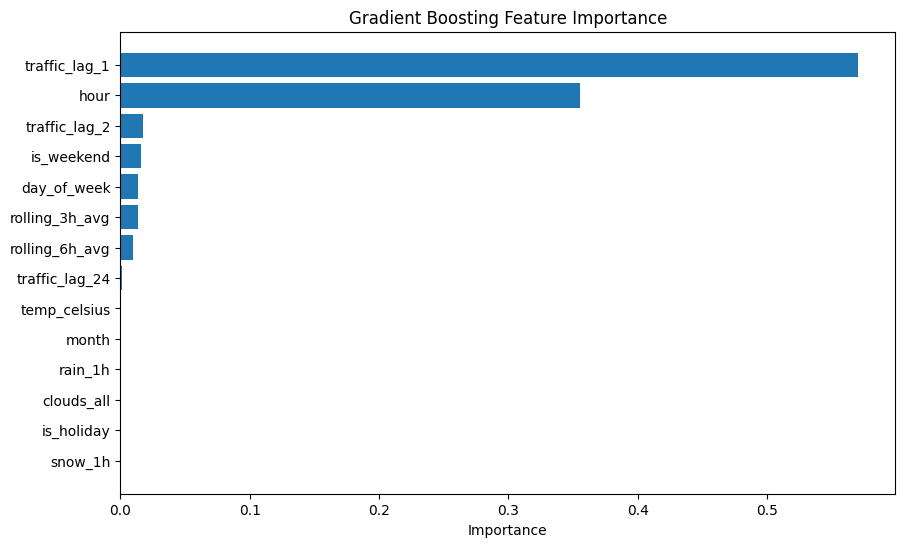

In [56]:
plt.figure(figsize=(10,6))

plt.barh(
    importance['Feature'],
    importance['Importance']
)

plt.xlabel('Importance')
plt.title('Gradient Boosting Feature Importance')
plt.gca().invert_yaxis()

plt.show()

Save the cleaned dataset

In [57]:
df.to_csv(
    'metro_traffic_week1_processed.csv',
    index=False
)

In [58]:
model_df.to_csv(
    'metro_traffic_model_data.csv',
    index=False
)

Week **2**

In [59]:
df = pd.read_csv("metro_traffic_week1_processed.csv")

df['date_time'] = pd.to_datetime(df['date_time'])
df = df.sort_values('date_time').reset_index(drop=True)

df.head()

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume,temp_celsius,...,is_weekend,is_holiday,is_raining,congestion_level,traffic_lag_1,traffic_lag_2,traffic_lag_24,rolling_3h_avg,rolling_6h_avg,traffic_1h_ahead
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545,15.13,...,0,0,0,High,NaN,NaN,NaN,NaN,NaN,4516.0
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516,16.21,...,0,0,0,High,5545.0,NaN,NaN,NaN,NaN,4767.0
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767,16.43,...,0,0,0,High,4516.0,5545.0,NaN,NaN,NaN,5026.0
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026,16.98,...,0,0,0,High,4767.0,4516.0,NaN,4942.666667,NaN,4918.0
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918,17.99,...,0,0,0,High,5026.0,4767.0,NaN,4769.666667,NaN,5181.0


current dataset doesn't have travel times. For Week 2, we can analyze traffic-volume variability as a proxy for demand reliability, without claiming it measures actual commute reliability.

The coefficient of variation (cv_percent) tells you how variable traffic volume is relative to its average.

In [60]:
reliability = df.groupby('hour')['traffic_volume'].agg(
    mean_volume='mean',
    std_volume='std',
    p90_volume=lambda x: x.quantile(0.90),
    p95_volume=lambda x: x.quantile(0.95)
)

reliability['cv_percent'] = (
    reliability['std_volume'] /
    reliability['mean_volume'].replace(0, np.nan)
) * 100

reliability

,mean_volume,std_volume,p90_volume,p95_volume,cv_percent
hour,,,,,
0,834.984774,380.940778,1404.5,1538.00,45.622482
1,516.339033,227.188304,857.8,958.00,43.999831
2,388.353640,168.196955,648.2,719.00,43.310256
3,371.090864,67.188107,439.0,485.80,18.105568
4,702.551889,233.880132,914.0,942.50,33.290087
5,2094.573437,1008.377374,2999.8,3050.70,48.142374
6,4140.503594,2073.217328,5884.4,5982.70,50.071622
7,4740.181337,2215.390808,6738.2,6857.30,46.736415
8,4587.497115,1669.276403,6156.0,6261.00,36.387519


**Visualize hourly traffic variability** - This helps identify hours when traffic demand is especially high or variable.

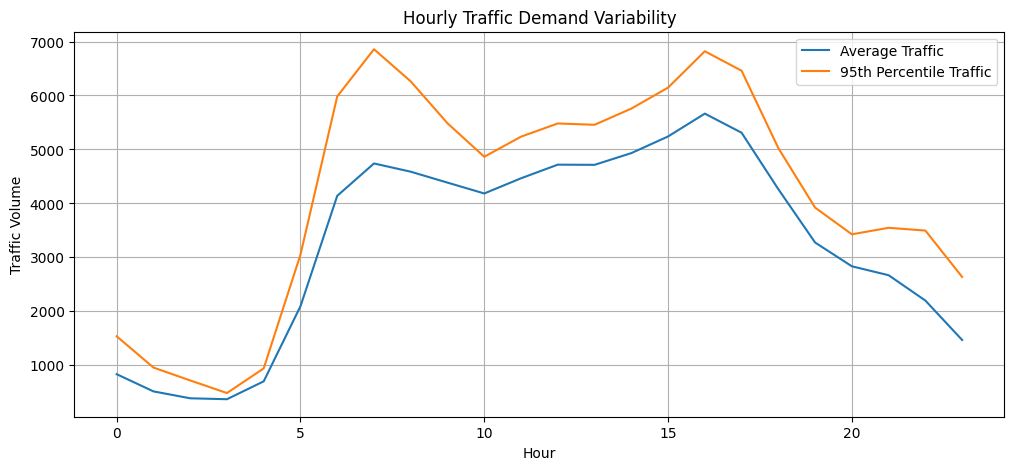

In [61]:
plt.figure(figsize=(12, 5))

plt.plot(
    reliability.index,
    reliability['mean_volume'],
    label='Average Traffic'
)

plt.plot(
    reliability.index,
    reliability['p95_volume'],
    label='95th Percentile Traffic'
)

plt.xlabel('Hour')
plt.ylabel('Traffic Volume')
plt.title('Hourly Traffic Demand Variability')
plt.legend()
plt.grid()
plt.show()

**Weather impact analysis** -
Find out whether traffic volume changes during different weather conditions.

In [62]:
weather_analysis = df.groupby('weather_main')['traffic_volume'].agg(
    ['mean', 'median', 'count']
).sort_values('mean', ascending=False)

weather_analysis

,mean,median,count
weather_main,,,
Clouds,3617.989115,4071.0,15158
Haze,3502.101471,3987.0,1360
Rain,3317.905501,3497.5,5672
Drizzle,3292.189560,3475.0,1820
Smoke,3237.650000,3612.0,20
Clear,3055.614465,3044.0,13384
Snow,3016.321391,3080.0,2875
Thunderstorm,2999.431752,2969.0,1033
Mist,2933.343923,2800.0,5949


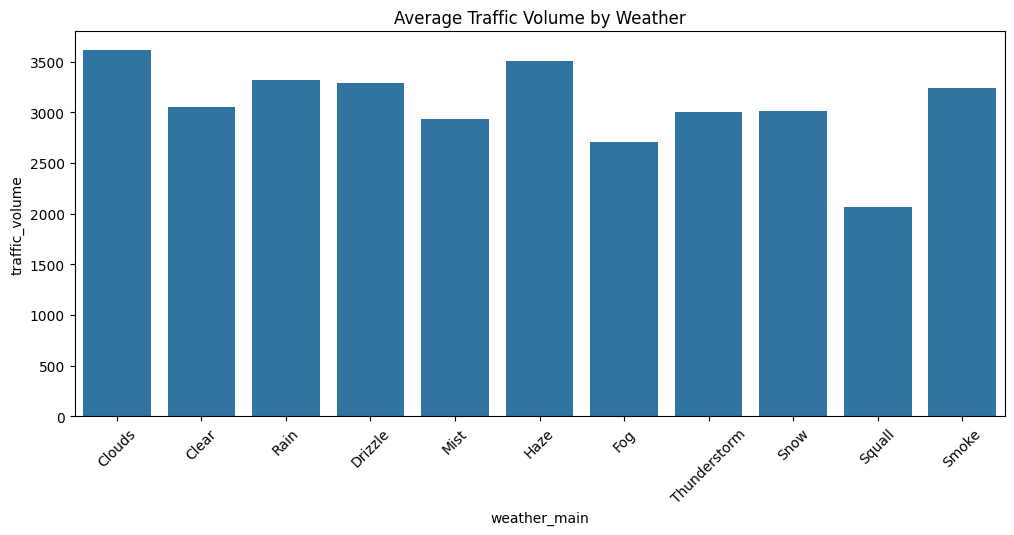

In [63]:
plt.figure(figsize=(12, 5))

sns.barplot(
    data=df,
    x='weather_main',
    y='traffic_volume',
    estimator=np.mean,
    errorbar=None
)

plt.xticks(rotation=45)
plt.title('Average Traffic Volume by Weather')
plt.show()

Holiday impact analysis

In [64]:
df['is_holiday'] = (
    df['holiday']
    .fillna('None')
    .astype(str)
    .str.strip()
    .ne('None')
    .astype(int)
)

df.groupby('is_holiday')['traffic_volume'].mean()

,traffic_volume
is_holiday,
0,3262.652766
1,865.442623


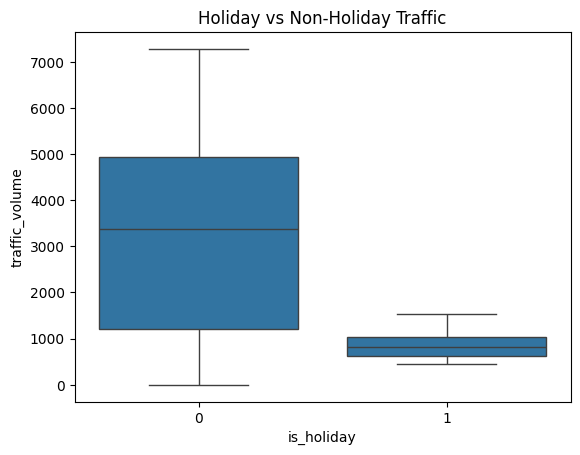

In [65]:
sns.boxplot(
    data=df,
    x='is_holiday',
    y='traffic_volume'
)

plt.title('Holiday vs Non-Holiday Traffic')
plt.show()

**External-factor correlation**

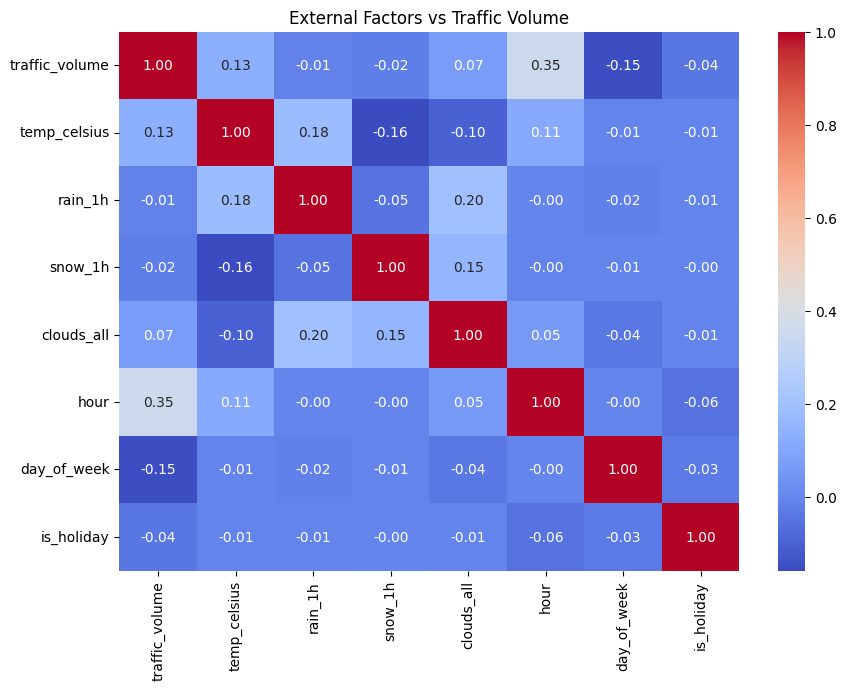

In [66]:
cols = [
    'traffic_volume',
    'temp_celsius',
    'rain_1h',
    'snow_1h',
    'clouds_all',
    'hour',
    'day_of_week',
    'is_holiday'
]

corr = df[cols].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('External Factors vs Traffic Volume')
plt.show()

- Positive correlation: two variables tend to increase together.
- Negative correlation: one tends to decrease as the other increases.
- Near zero: little linear relationship.
Correlation does not prove causation.

**GRU and LSTM**

Prepare time-series data.
The goal is to predict traffic volume 1 hour and 2 hours ahead.
One issue in this dataset is that multiple rows may share the same timestamp because of different weather descriptions, and some hourly timestamps may be missing.
First create a consistent hourly traffic series:

In [67]:
traffic = (
    df.groupby('date_time')['traffic_volume']
    .mean()
    .sort_index()
    .resample('h')
    .mean()
)

print("Missing hourly periods:", traffic.isna().sum())

Missing hourly periods: 11976


**For a simple baseline, fill gaps using past observations only:**

In [68]:
traffic = traffic.ffill(limit=3).dropna()

**Train-test split and scaling** -
We'll use the previous 24 hours to predict the next hour.

In [69]:
from sklearn.preprocessing import MinMaxScaler

values = traffic.values.reshape(-1, 1)

split = int(len(values) * 0.8)

scaler = MinMaxScaler()

train_scaled = scaler.fit_transform(values[:split])
all_scaled = scaler.transform(values)

the scaler is fitted only on training data to avoid data leakage.

**Create sequences** - Each input contains 24 hourly traffic observations. The target is the next hour's volume.

In [70]:
import numpy as np

def create_sequences(data, lookback=24):
    X, y = [], []

    for i in range(lookback, len(data)):
        X.append(data[i-lookback:i])
        y.append(data[i])

    return np.array(X), np.array(y)


X_all, y_all = create_sequences(all_scaled, 24)

target_positions = np.arange(24, len(values))

train_mask = target_positions < split
test_mask = target_positions >= split

X_train = X_all[train_mask]
X_test = X_all[test_mask]

y_train = y_all[train_mask]
y_test = y_all[test_mask]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (34979, 24, 1)
X_test: (8751, 24, 1)
y_train: (34979, 1)
y_test: (8751, 1)


**Build the LSTM model** -  TensorFlow/Keras is a convenient alternative to the proposed PyTorch stack.

In [71]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Input
from tensorflow.keras.callbacks import EarlyStopping

lstm_model = Sequential([
    Input(shape=(24, 1)),
    LSTM(64),
    Dense(32, activation='relu'),
    Dense(1)
])

lstm_model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

history = lstm_model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.2,
    shuffle=False,
    callbacks=[
        EarlyStopping(
            patience=5,
            restore_best_weights=True
        )
    ]
)

Epoch 1/30
875/875 ━━━━━━━━━━━━━━━━━━━━ 15s 15ms/step - loss: 0.0177 - mae: 0.0916 - val_loss: 0.0052 - val_mae: 0.0509
Epoch 2/30
875/875 ━━━━━━━━━━━━━━━━━━━━ 21s 15ms/step - loss: 0.0073 - mae: 0.0580 - val_loss: 0.0036 - val_mae: 0.0429
Epoch 3/30
875/875 ━━━━━━━━━━━━━━━━━━━━ 20s 14ms/step - loss: 0.0064 - mae: 0.0528 - val_loss: 0.0028 - val_mae: 0.0377
Epoch 4/30
875/875 ━━━━━━━━━━━━━━━━━━━━ 13s 14ms/step - loss: 0.0059 - mae: 0.0498 - val_loss: 0.0028 - val_mae: 0.0357
Epoch 5/30
875/875 ━━━━━━━━━━━━━━━━━━━━ 20s 14ms/step - loss: 0.0056 - mae: 0.0480 - val_loss: 0.0028 - val_mae: 0.0356
Epoch 6/30
875/875 ━━━━━━━━━━━━━━━━━━━━ 21s 14ms/step - loss: 0.0054 - mae: 0.0470 - val_loss: 0.0026 - val_mae: 0.0346
Epoch 7/30
875/875 ━━━━━━━━━━━━━━━━━━━━ 12s 14ms/step - loss: 0.0053 - mae: 0.0461 - val_loss: 0.0027 - val_mae: 0.0352
Epoch 8/30
875/875 ━━━━━━━━━━━━━━━━━━━━ 20s 14ms/step - loss: 0.0052 - mae: 0.0456 - val_loss: 0.0026 - val_mae: 0.0353
Epoch 9/30
875/875 ━━━━━━━━━━━━━━━━━━━━ 

**Build the GRU model**

In [72]:
from tensorflow.keras.layers import GRU

gru_model = Sequential([
    Input(shape=(24, 1)),
    GRU(64),
    Dense(32, activation='relu'),
    Dense(1)
])

gru_model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

gru_model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.2,
    shuffle=False,
    callbacks=[
        EarlyStopping(
            patience=5,
            restore_best_weights=True
        )
    ]
)

Epoch 1/30
875/875 ━━━━━━━━━━━━━━━━━━━━ 17s 17ms/step - loss: 0.0147 - mae: 0.0811 - val_loss: 0.0081 - val_mae: 0.0683
Epoch 2/30
875/875 ━━━━━━━━━━━━━━━━━━━━ 15s 17ms/step - loss: 0.0076 - mae: 0.0605 - val_loss: 0.0033 - val_mae: 0.0404
Epoch 3/30
875/875 ━━━━━━━━━━━━━━━━━━━━ 20s 17ms/step - loss: 0.0060 - mae: 0.0508 - val_loss: 0.0031 - val_mae: 0.0393
Epoch 4/30
875/875 ━━━━━━━━━━━━━━━━━━━━ 22s 19ms/step - loss: 0.0054 - mae: 0.0468 - val_loss: 0.0028 - val_mae: 0.0365
Epoch 5/30
875/875 ━━━━━━━━━━━━━━━━━━━━ 15s 17ms/step - loss: 0.0052 - mae: 0.0457 - val_loss: 0.0026 - val_mae: 0.0349
Epoch 6/30
875/875 ━━━━━━━━━━━━━━━━━━━━ 20s 17ms/step - loss: 0.0051 - mae: 0.0451 - val_loss: 0.0027 - val_mae: 0.0360
Epoch 7/30
875/875 ━━━━━━━━━━━━━━━━━━━━ 15s 17ms/step - loss: 0.0050 - mae: 0.0447 - val_loss: 0.0025 - val_mae: 0.0350
Epoch 8/30
875/875 ━━━━━━━━━━━━━━━━━━━━ 15s 17ms/step - loss: 0.0050 - mae: 0.0441 - val_loss: 0.0024 - val_mae: 0.0339
Epoch 9/30
875/875 ━━━━━━━━━━━━━━━━━━━━ 

**Compare LSTM and GRU** - Compare these with your Week 1 Gradient Boosting model using the same test period.

In [73]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

lstm_pred = scaler.inverse_transform(
    lstm_model.predict(X_test, verbose=0)
)

gru_pred = scaler.inverse_transform(
    gru_model.predict(X_test, verbose=0)
)

actual = scaler.inverse_transform(y_test)

comparison = pd.DataFrame({
    'Model': ['LSTM', 'GRU'],
    'MAE': [
        mean_absolute_error(actual, lstm_pred),
        mean_absolute_error(actual, gru_pred)
    ],
    'RMSE': [
        np.sqrt(mean_squared_error(actual, lstm_pred)),
        np.sqrt(mean_squared_error(actual, gru_pred))
    ]
})

comparison

,Model,MAE,RMSE
0,LSTM,207.622168,298.009085
1,GRU,200.963353,287.254872


**Actual vs predicted graph**

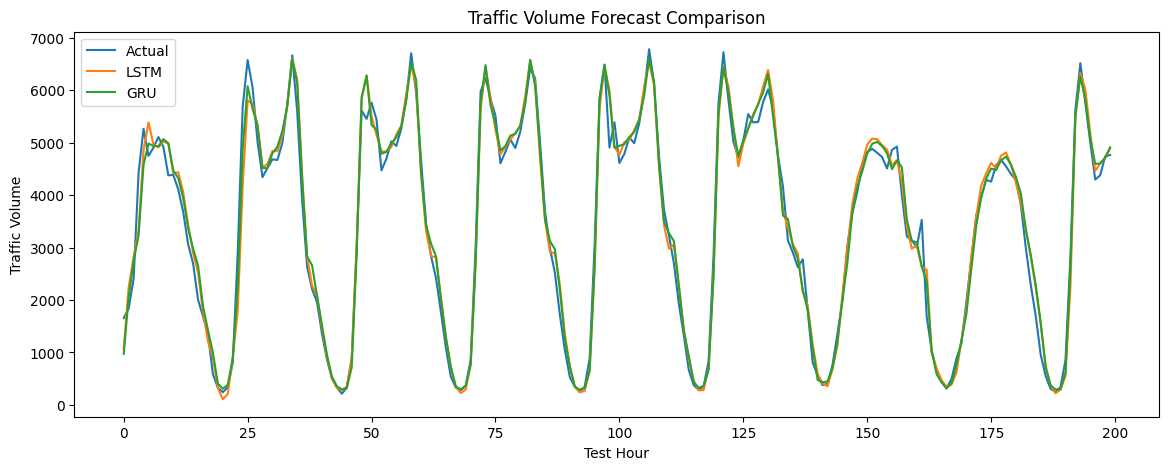

In [74]:
plt.figure(figsize=(14, 5))

plt.plot(actual[:200], label='Actual')
plt.plot(lstm_pred[:200], label='LSTM')
plt.plot(gru_pred[:200], label='GRU')

plt.title('Traffic Volume Forecast Comparison')
plt.xlabel('Test Hour')
plt.ylabel('Traffic Volume')
plt.legend()
plt.show()

**Signal timing optimizer** -
 Demonstration using predicted traffic
Suppose an intersection has four incoming approaches.
The following numbers are illustrative, not measurements from the Metro Interstate dataset.

In [75]:
predicted_flow = {
    'North': 800,
    'South': 600,
    'East': 400,
    'West': 200
}

Assume four independent signal phases and a total of 100 seconds of green time.

In [76]:
total_green = 100

total_flow = sum(predicted_flow.values())

green_times = {
    direction: total_green * flow / total_flow
    for direction, flow in predicted_flow.items()
}

for direction, seconds in green_times.items():
    print(direction, round(seconds, 1), 'seconds')

North 40.0 seconds
South 30.0 seconds
East 20.0 seconds
West 10.0 seconds


This is a proportional green-allocation demonstration, not a validated optimizer that minimizes waiting time. A real optimizer must account for saturation flow, compatible movements, pedestrian clearance, minimum green time, lost time and intersection geometry.
For this project, use this as an initial prototype and develop a Webster-based or simulation-tested optimizer when actual intersection data is available.

**Save models**

In [77]:
lstm_model.save('traffic_lstm.keras')
gru_model.save('traffic_gru.keras')

**Save the scaler**

In [78]:
import joblib

joblib.dump(scaler, 'traffic_scaler.pkl')

['traffic_scaler.pkl']

**Week 2 Analysis **- we analyzed traffic variability and external factors such as weather and holidays. We developed LSTM and GRU models to forecast future traffic volume and compared their prediction performance. We also implemented an initial traffic-signal timing recommendation prototype based on estimated traffic demand."